# DZ03 — Error Analysis + One Hypothesis + Fine-tune

**Course:** Computer Vision Engineering for DefenceTech  
**Author:** Serhii Polishchuk  
**Report:** 04 Detection & Error Analysis Report — Part 2  

Continues DZ01 (dataset audit) and DZ02 (detection baseline).

**Steps in this notebook:**
1. Point «before» (B0) — fixed config & metrics from Part 1
2. Prediction review — GT + pred on selected val frames
3. Error table (next)
4. Hypothesis (next)
5. Fine-tune on train (next)
6. Re-evaluation (next)

## 0. Setup

In [ ]:
!pip install -q ultralytics opencv-python-headless

import os, time, json, random, shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from tqdm.auto import tqdm

from ultralytics import YOLO
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    HARDWARE = f"GPU: {torch.cuda.get_device_name(0)}"
else:
    HARDWARE = "CPU"
print("Hardware:", HARDWARE)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
Hardware: GPU: Tesla T4


## 1. Точка «до» (B0) — фіксуємо baseline з Part 1 / ДЗ2

Це **точка відліку**. Усі порівняння «після» донавчання йдуть відносно цих чисел і цієї конфігурації.

З ДЗ2 (після виправлення мапінгу VisDrone→COCO):
- Модель: YOLOv8n, COCO pretrained
- imgsz=640 (основний B0; imgsz=1280 був контрольованою зміною I1)
- conf=0.25, iou=0.7, split=val

In [ ]:
# ========== B0 — POINT "BEFORE" (from DZ02 Part 1) ==========
B0 = {
    "id": "B0",
    "description": "Zero-shot YOLOv8n COCO pretrained on VisDrone val (correct class mapping)",
    "model": "yolov8n.pt",
    "model_source": "Ultralytics YOLOv8n (COCO pretrained)",
    "imgsz": 640,
    "conf": 0.25,
    "iou": 0.7,
    "eval_split": "val",
    "hardware": HARDWARE,
    "seed": SEED,
    # Metrics from DZ02 (after VisDrone→COCO mapping fix)
    "mAP50-95": 0.0529,
    "mAP50": 0.0800,
    "precision": 0.4671,
    "recall": 0.1063,
    "mAP50-95_small": 0.0025,
    "mAP50-95_medium": 0.1474,
    "mAP50-95_large": 0.1851,
    "peak_gpu_memory_mb": 274,
}

# I1 — controlled change from DZ02 (kept separate from fine-tune effect)
I1 = {
    "id": "I1",
    "description": "Same as B0 but imgsz=1280",
    "imgsz": 1280,
    "mAP50-95": 0.1006,
    "mAP50": 0.1532,
    "precision": 0.4863,
    "recall": 0.2084,
    "mAP50-95_small": 0.0230,
    "mAP50-95_medium": 0.2299,
    "mAP50-95_large": 0.2414,
    "peak_gpu_memory_mb": 994,
}

print("=== B0 (точка «до») ===")
for k, v in B0.items():
    print(f"  {k}: {v}")

print("\n=== I1 (контрольована зміна imgsz, окремо від fine-tune) ===")
for k, v in I1.items():
    print(f"  {k}: {v}")

print("\nДля error analysis і fine-tune використовуємо B0 (imgsz=640) як основну точку «до».")

=== B0 (точка «до») ===
  id: B0
  description: Zero-shot YOLOv8n COCO pretrained on VisDrone val (correct class mapping)
  model: yolov8n.pt
  model_source: Ultralytics YOLOv8n (COCO pretrained)
  imgsz: 640
  conf: 0.25
  iou: 0.7
  eval_split: val
  hardware: GPU: Tesla T4
  seed: 42
  mAP50-95: 0.0529
  mAP50: 0.08
  precision: 0.4671
  recall: 0.1063
  mAP50-95_small: 0.0025
  mAP50-95_medium: 0.1474
  mAP50-95_large: 0.1851
  peak_gpu_memory_mb: 274

=== I1 (контрольована зміна imgsz, окремо від fine-tune) ===
  id: I1
  description: Same as B0 but imgsz=1280
  imgsz: 1280
  mAP50-95: 0.1006
  mAP50: 0.1532
  precision: 0.4863
  recall: 0.2084
  mAP50-95_small: 0.023
  mAP50-95_medium: 0.2299
  mAP50-95_large: 0.2414
  peak_gpu_memory_mb: 994

Для error analysis і fine-tune використовуємо B0 (imgsz=640) як основну точку «до».


## 1b. Dataset + class mapping (той самий, що в ДЗ2)

In [ ]:
DATA_ROOT = Path("./datasets/VisDrone")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

URLS = {
    "VisDrone2019-DET-train": "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip",
    "VisDrone2019-DET-val":   "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip",
}

import zipfile, urllib.request

def download_and_extract(name, url, root):
    target_dir = root / name
    if target_dir.exists() and any(target_dir.rglob("*.jpg")):
        print(f"[SKIP] {name}")
        return
    zip_path = root / f"{name}.zip"
    print(f"[DOWNLOAD] {name} ...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(root)
    zip_path.unlink(missing_ok=True)
    print(f"[DONE] {name}")

for name, url in URLS.items():
    download_and_extract(name, url, DATA_ROOT)

[DOWNLOAD] VisDrone2019-DET-train ...
[DONE] VisDrone2019-DET-train
[DOWNLOAD] VisDrone2019-DET-val ...
[DONE] VisDrone2019-DET-val


In [ ]:
# VisDrone original category → COCO class id (same as DZ02 mentor fix)
VISDRONE_TO_COCO = {
    1: 0,   # pedestrian → person
    2: 0,   # people → person
    3: 1,   # bicycle → bicycle
    4: 2,   # car → car
    5: 2,   # van → car
    6: 7,   # truck → truck
    9: 5,   # bus → bus
    10: 3,  # motor → motorcycle
}

COCO_NAMES = {
    0: "person", 1: "bicycle", 2: "car", 3: "motorcycle",
    5: "bus", 7: "truck",
}

def convert_visdrone_to_coco_yolo(split_dir: Path):
    images_dir = split_dir / "images"
    ann_dir = split_dir / "annotations"
    labels_dir = split_dir / "labels_coco"
    labels_dir.mkdir(exist_ok=True)

    n = 0
    for ann_path in tqdm(list(ann_dir.glob("*.txt")), desc=f"Convert {split_dir.name}"):
        img_path = images_dir / (ann_path.stem + ".jpg")
        if not img_path.exists():
            continue
        with Image.open(img_path) as im:
            W, H = im.size
        lines = []
        with open(ann_path) as f:
            for row in f:
                parts = row.strip().split(",")
                if len(parts) < 6:
                    continue
                x, y, w, h = map(int, parts[:4])
                cat = int(parts[5])
                if cat not in VISDRONE_TO_COCO or w <= 0 or h <= 0:
                    continue
                cls = VISDRONE_TO_COCO[cat]
                xc, yc = (x + w / 2) / W, (y + h / 2) / H
                bw, bh = w / W, h / H
                lines.append(f"{cls} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
        with open(labels_dir / (ann_path.stem + ".txt"), "w") as f:
            f.writelines(lines)
        n += 1
    print(f"  → {n} label files")

for split_name in ["VisDrone2019-DET-train", "VisDrone2019-DET-val"]:
    sp = DATA_ROOT / split_name
    if sp.exists():
        convert_visdrone_to_coco_yolo(sp)
        # labels/ → labels_coco
        dst = sp / "labels"
        src = sp / "labels_coco"
        if dst.exists() and not dst.is_symlink():
            if not (sp / "labels_old").exists():
                dst.rename(sp / "labels_old")
            else:
                shutil.rmtree(dst)
        if not dst.exists():
            dst.symlink_to("labels_coco")

Convert VisDrone2019-DET-train:   0%|          | 0/6471 [00:00<?, ?it/s]

  → 6471 label files


Convert VisDrone2019-DET-val:   0%|          | 0/548 [00:00<?, ?it/s]

  → 548 label files


In [ ]:
tmp = YOLO("yolov8n.pt")
coco_names = tmp.names
names_block = "\n".join([f"  {i}: {n}" for i, n in coco_names.items()])
yaml_content = f"""
path: {DATA_ROOT.resolve()}
train: VisDrone2019-DET-train/images
val: VisDrone2019-DET-val/images

names:
{names_block}
"""
yaml_path = DATA_ROOT / "visdrone_coco.yaml"
with open(yaml_path, "w") as f:
    f.write(yaml_content.strip() + "\n")
print("yaml:", yaml_path)

yaml: datasets/VisDrone/visdrone_coco.yaml


## 2. Перегляд передбачень (Prediction review)

**Мета:** відібрати кадри для ручного аналізу помилок, намалювати GT і predictions в одних координатах.

**Спосіб відбору:**
- випадкова вибірка з val (seed=42) — 24 кадри
- плюс кілька кадрів з великою кількістю small-об’єктів (де очікуємо найбільше помилок)

Список кадрів зберігається у `review_frames.txt` для відтворюваності.

In [ ]:
VAL_IMAGES = DATA_ROOT / "VisDrone2019-DET-val" / "images"
VAL_LABELS = DATA_ROOT / "VisDrone2019-DET-val" / "labels"
OUT_DIR = Path("./dz03_review")
OUT_DIR.mkdir(exist_ok=True)

all_imgs = sorted(VAL_IMAGES.glob("*.jpg"))
print(f"Val images: {len(all_imgs)}")

# Count small objects per image (area < 32^2)
def count_small(label_path, img_path):
    with Image.open(img_path) as im:
        W, H = im.size
    n_small = 0
    if not label_path.exists():
        return 0
    with open(label_path) as f:
        for line in f:
            p = line.strip().split()
            if len(p) < 5:
                continue
            bw, bh = float(p[3]), float(p[4])
            if bw * W * bh * H < 32 ** 2:
                n_small += 1
    return n_small

small_counts = []
for img_path in tqdm(all_imgs, desc="Count small"):
    lp = VAL_LABELS / (img_path.stem + ".txt")
    small_counts.append((img_path, count_small(lp, img_path)))

small_counts.sort(key=lambda x: -x[1])

# Selection: 12 random + 12 with most small objects
rng = random.Random(SEED)
random_pick = rng.sample(all_imgs, 12)
hard_pick = [p for p, _ in small_counts[:12]]

review_set = []
seen = set()
for p in hard_pick + random_pick:
    if p.stem not in seen:
        review_set.append(p)
        seen.add(p.stem)
    if len(review_set) >= 24:
        break

review_list_path = OUT_DIR / "review_frames.txt"
with open(review_list_path, "w") as f:
    for p in review_set:
        f.write(p.name + "\n")

print(f"Review frames: {len(review_set)}")
print(f"Saved list: {review_list_path}")
print("First 8:", [p.name for p in review_set[:8]])

Val images: 548


Count small:   0%|          | 0/548 [00:00<?, ?it/s]

Review frames: 24
Saved list: dz03_review/review_frames.txt
First 8: ['0000295_02400_d_0000033.jpg', '0000295_01800_d_0000030.jpg', '0000295_02000_d_0000031.jpg', '0000295_01000_d_0000026.jpg', '0000295_01200_d_0000027.jpg', '0000295_01400_d_0000028.jpg', '0000295_02900_d_0000034.jpg', '0000295_00600_d_0000024.jpg']


In [ ]:
# Load B0 model and run predictions on review frames
model = YOLO(B0["model"])

COLORS_GT = (0, 255, 0)      # green = GT
COLORS_PRED = (255, 0, 0)    # red = prediction

def yolo_to_xyxy(xc, yc, bw, bh, W, H):
    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H
    return [x1, y1, x2, y2]

def draw_boxes(img_bgr, boxes_xyxy, labels, color, thickness=2):
    for box, lab in zip(boxes_xyxy, labels):
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(img_bgr, (x1, y1), (x2, y2), color, thickness)
        cv2.putText(img_bgr, lab, (x1, max(0, y1 - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)
    return img_bgr

def load_gt_boxes(label_path, W, H):
    boxes, labels = [], []
    if not label_path.exists():
        return boxes, labels
    with open(label_path) as f:
        for line in f:
            p = line.strip().split()
            if len(p) < 5:
                continue
            cls = int(float(p[0]))
            xc, yc, bw, bh = map(float, p[1:5])
            boxes.append(yolo_to_xyxy(xc, yc, bw, bh, W, H))
            labels.append(COCO_NAMES.get(cls, str(cls)))
    return boxes, labels

viz_dir = OUT_DIR / "viz_b0"
viz_dir.mkdir(exist_ok=True)

print(f"Running B0 inference on {len(review_set)} frames (imgsz={B0['imgsz']})...")
for img_path in tqdm(review_set):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]

    # GT
    gt_boxes, gt_labels = load_gt_boxes(VAL_LABELS / (img_path.stem + ".txt"), W, H)

    # Predictions
    r = model.predict(str(img_path), imgsz=B0["imgsz"], conf=B0["conf"],
                      iou=B0["iou"], verbose=False)[0]
    pred_boxes, pred_labels = [], []
    if r.boxes is not None and len(r.boxes):
        for b in r.boxes:
            cls = int(b.cls.item())
            cf = float(b.conf.item())
            # only mapped classes of interest
            if cls not in COCO_NAMES:
                continue
            pred_boxes.append(b.xyxy[0].cpu().numpy().tolist())
            pred_labels.append(f"{COCO_NAMES[cls]} {cf:.2f}")

    # Side-by-side: left GT, right Pred, or overlay both
    canvas = img.copy()
    canvas = draw_boxes(canvas, gt_boxes, gt_labels, COLORS_GT, 2)
    canvas = draw_boxes(canvas, pred_boxes, pred_labels, COLORS_PRED, 2)

    # legend
    cv2.putText(canvas, "GT=green  PRED=red", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

    out_path = viz_dir / f"{img_path.stem}_gt_pred.jpg"
    cv2.imwrite(str(out_path), canvas)

print(f"Saved visualizations → {viz_dir}")
print(f"GT boxes (green) and predictions (red) in the SAME image coordinates.")

Running B0 inference on 24 frames (imgsz=640)...


  0%|          | 0/24 [00:00<?, ?it/s]

Saved visualizations → dz03_review/viz_b0
GT boxes (green) and predictions (red) in the SAME image coordinates.


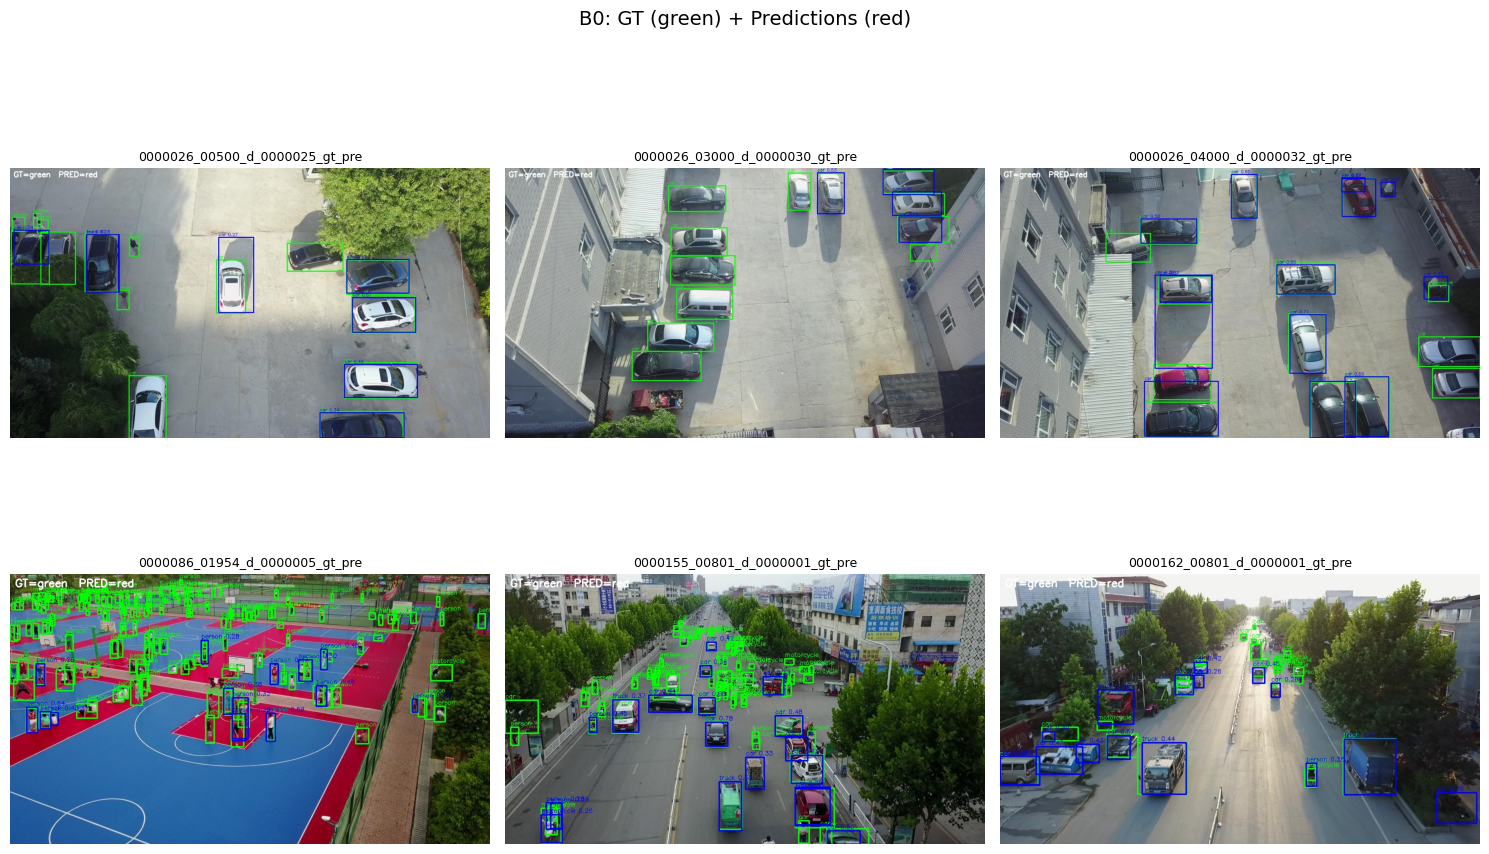


=== Для звіту (розділ 2.1) ===
Список кадрів ручного перегляду: dz03_review/review_frames.txt
Кількість: 24
Спосіб відбору: 12 кадрів з найбільшою кількістю small-об'єктів + 12 випадкових (seed=42)
Візуалізація: GT (зелений) і predictions (червоний) на одному зображенні, ті самі координати
Папка з картинками: dz03_review/viz_b0


In [ ]:
# Show a few examples in the notebook
viz_files = sorted(viz_dir.glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, vp in zip(axes.flat, viz_files):
    im = cv2.cvtColor(cv2.imread(str(vp)), cv2.COLOR_BGR2RGB)
    ax.imshow(im)
    ax.set_title(vp.stem[:30], fontsize=9)
    ax.axis("off")
plt.suptitle("B0: GT (green) + Predictions (red)", fontsize=14)
plt.tight_layout()
plt.show()

print("\n=== Для звіту (розділ 2.1) ===")
print(f"Список кадрів ручного перегляду: {review_list_path}")
print(f"Кількість: {len(review_set)}")
print("Спосіб відбору: 12 кадрів з найбільшою кількістю small-об'єктів + 12 випадкових (seed=42)")
print("Візуалізація: GT (зелений) і predictions (червоний) на одному зображенні, ті самі координати")
print(f"Папка з картинками: {viz_dir}")

## 3. Таблиця помилок (Error table)

На основі 24 review-кадрів і метрик B0.

| Тип помилки | Опис | Спостереження | Вплив |
|-------------|------|---------------|-------|
| **FN small** | GT є, pred немає; small objects | Майже на всіх кадрах з людьми / далеким трафіком | **Домінуюча** (recall 0.11, mAP_s 0.0025) |
| FN medium/large | Пропуск більших об'єктів | Парковки, частина авто | Середній |
| FP | Pred є, GT немає | Рідко | Низький |
| Localization | Бокс зсунутий | На знайдених авто | Вторинний |
| Wrong class | Невірний клас | Майже не спостерігалось | Низький |

**Домінуюча проблема:** FN на small-об'єктах (пропуск дрібних цілей з дрона).

## 4. Гіпотеза (одна, до навчання)

| Поле | Зміст |
|------|-------|
| **Можлива причина** | Zero-shot COCO-модель не адаптована до ракурсу з дрона і типових розмірів VisDrone; ~69% GT — small, mAP_small ≈ 0 |
| **Докази** | Review: багато зелених боксів без червоних; B0 recall=0.106, mAP50-95_small=0.0025 |
| **Запропонована зміна** | Донавчання YOLOv8n на VisDrone **train** (той самий мапінг COCO), imgsz=640, кілька епох |
| **Очікуваний ефект** | Зростання mAP50-95 і recall на val; менше FN на small на тих самих review-кадрах |
| **Коли гіпотеза НЕ підтверджена** | Якщо після train mAP50-95 / recall не зростуть (або впадуть), або FN на review не зменшиться; або з'являться сильні регресії (різке падіння precision) |

In [ ]:
HYPOTHESIS = {
    "id": "H1",
    "cause": "COCO zero-shot not adapted to drone view / small objects on VisDrone",
    "evidence": "FN dominates on review frames; B0 recall=0.106, mAP_small=0.0025, ~69% GT small",
    "change": "Fine-tune yolov8n.pt on VisDrone train, imgsz=640, same COCO mapping",
    "expected": "Higher mAP50-95 and recall on val; fewer FN on same review frames",
    "not_supported_if": "mAP/recall do not improve, or strong precision regression",
}
print("=== HYPOTHESIS H1 ===")
for k, v in HYPOTHESIS.items():
    print(f"  {k}: {v}")

=== HYPOTHESIS H1 ===
  id: H1
  cause: COCO zero-shot not adapted to drone view / small objects on VisDrone
  evidence: FN dominates on review frames; B0 recall=0.106, mAP_small=0.0025, ~69% GT small
  change: Fine-tune yolov8n.pt on VisDrone train, imgsz=640, same COCO mapping
  expected: Higher mAP50-95 and recall on val; fewer FN on same review frames
  not_supported_if: mAP/recall do not improve, or strong precision regression


## 5. Донавчання (fine-tune) — лише на train

- Початкові ваги: `yolov8n.pt` (B0)
- Дані: тільки **train** (val не змішуємо)
- imgsz=640 (як B0 — щоб ефект був від навчання, не від resolution)
- Епохи: 15 (достатньо для перевірки гіпотези в Colab)
- Зберігаємо best.pt, аргументи, лог

In [ ]:
# ADD LEARNING
TRAIN_CFG = {
    "model": "yolov8n.pt",
    "data": str(yaml_path),
    "epochs": 15,
    "imgsz": 640,
    "batch": 16,
    "patience": 5,
    "seed": SEED,
    "project": "dz03_runs",
    "name": "finetune_b0",
    "exist_ok": True,
}

print("=== TRAIN CONFIG ===")
for k, v in TRAIN_CFG.items():
    print(f"  {k}: {v}")

model_ft = YOLO(TRAIN_CFG["model"])

print("\nStarting fine-tune on train only...")
t0 = time.time()
train_results = model_ft.train(
    data=TRAIN_CFG["data"],
    epochs=TRAIN_CFG["epochs"],
    imgsz=TRAIN_CFG["imgsz"],
    batch=TRAIN_CFG["batch"],
    patience=TRAIN_CFG["patience"],
    seed=TRAIN_CFG["seed"],
    project=TRAIN_CFG["project"],
    name=TRAIN_CFG["name"],
    exist_ok=TRAIN_CFG["exist_ok"],
    plots=True,
    verbose=True,
)
train_time = time.time() - t0
print(f"\nFine-tune finished in {train_time/60:.1f} min")

# Path to best weights
best_pt = Path(TRAIN_CFG["project"]) / TRAIN_CFG["name"] / "weights" / "best.pt"
last_pt = Path(TRAIN_CFG["project"]) / TRAIN_CFG["name"] / "weights" / "last.pt"
print("best.pt:", best_pt, "exists:" , best_pt.exists())
print("last.pt:", last_pt, "exists:", last_pt.exists())

=== TRAIN CONFIG ===
  model: yolov8n.pt
  data: datasets/VisDrone/visdrone_coco.yaml
  epochs: 15
  imgsz: 640
  batch: 16
  patience: 5
  seed: 42
  project: dz03_runs
  name: finetune_b0
  exist_ok: True

Starting fine-tune on train only...
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/VisDrone/visdrone_coco.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=

## 6. Повторне оцінювання (після fine-tune)

Ті самі умови, що B0: val, imgsz=640, conf=0.25, iou=0.7, той самий yaml/мапінг.

In [ ]:
from pathlib import Path
from ultralytics import YOLO

best_pt = Path("/content/runs/detect/dz03_runs/finetune_b0/weights/best.pt")
print("best exists:", best_pt.exists())

model_after = YOLO(str(best_pt))
print("Model loaded OK")

best exists: True
Model loaded OK


In [ ]:
import time
import torch

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

t0 = time.time()
after_results = model_after.val(
    data=str(yaml_path),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    split="val",
    plots=False,
    verbose=True,
)
after_time = time.time() - t0

AFTER = {
    "mAP50-95": float(after_results.box.map),
    "mAP50": float(after_results.box.map50),
    "precision": float(after_results.box.mp),
    "recall": float(after_results.box.mr),
    "time_s": after_time,
}
print("=== AFTER ===")
for k, v in AFTER.items():
    print(f"  {k}: {v}")

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2373.6±809.3 MB/s, size: 142.5 KB)
val: Scanning /content/datasets/VisDrone/VisDrone2019-DET-val/labels.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 164.2Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.1it/s 5.8s
                   all        548      37182      0.525      0.259      0.222      0.133
                person        531      13969      0.562      0.264   

In [ ]:
weights_after = str(best_pt) if best_pt.exists() else str(last_pt)
model_after = YOLO(weights_after)

print(f"Evaluating: {weights_after}")
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

t0 = time.time()
after_results = model_after.val(
    data=str(yaml_path),
    imgsz=B0["imgsz"],
    conf=B0["conf"],
    iou=B0["iou"],
    split="val",
    plots=False,
    verbose=True,
)
after_time = time.time() - t0

AFTER = {
    "mAP50-95": float(after_results.box.map),
    "mAP50": float(after_results.box.map50),
    "precision": float(after_results.box.mp),
    "recall": float(after_results.box.mr),
    "time_s": after_time,
}
if torch.cuda.is_available():
    AFTER["peak_gpu_memory_mb"] = torch.cuda.max_memory_allocated() / 1024**2

print("\n=== AFTER (fine-tuned) ===")
for k, v in AFTER.items():
    if isinstance(v, float):
        print(f"  {k}: {v:.4f}")
    else:
        print(f"  {k}: {v}")

In [ ]:
# Before / After comparison table
comparison = pd.DataFrame({
    "Metric": ["mAP50-95", "mAP50", "Precision", "Recall"],
    "B0 (before)": [
        f"{B0['mAP50-95']:.4f}",
        f"{B0['mAP50']:.4f}",
        f"{B0['precision']:.4f}",
        f"{B0['recall']:.4f}",
    ],
    "After fine-tune": [
        f"{AFTER['mAP50-95']:.4f}",
        f"{AFTER['mAP50']:.4f}",
        f"{AFTER['precision']:.4f}",
        f"{AFTER['recall']:.4f}",
    ],
})
print("=== BEFORE / AFTER (hypothesis check) ===")
display(comparison)

delta_map = AFTER["mAP50-95"] - B0["mAP50-95"]
delta_rec = AFTER["recall"] - B0["recall"]
print(f"\nΔ mAP50-95: {delta_map:+.4f}")
print(f"Δ recall:    {delta_rec:+.4f}")

if delta_map > 0 and delta_rec > 0:
    print("\n→ Гіпотеза H1 ПІДТРИМАНА: mAP і recall зросли після донавчання.")
elif delta_map > 0:
    print("\n→ Гіпотеза H1 частково підтримана (mAP↑).")
else:
    print("\n→ Гіпотеза H1 НЕ підтверджена за mAP (див. умови not_supported_if).")

## 6b. Ті самі review-кадри після fine-tune

Візуалізація GT + pred на **тому ж списку** кадрів — перевірка цільового ефекту (менше FN) і регресій.

Running AFTER inference on 24 review frames...


  0%|          | 0/24 [00:00<?, ?it/s]

Saved → dz03_review/viz_after


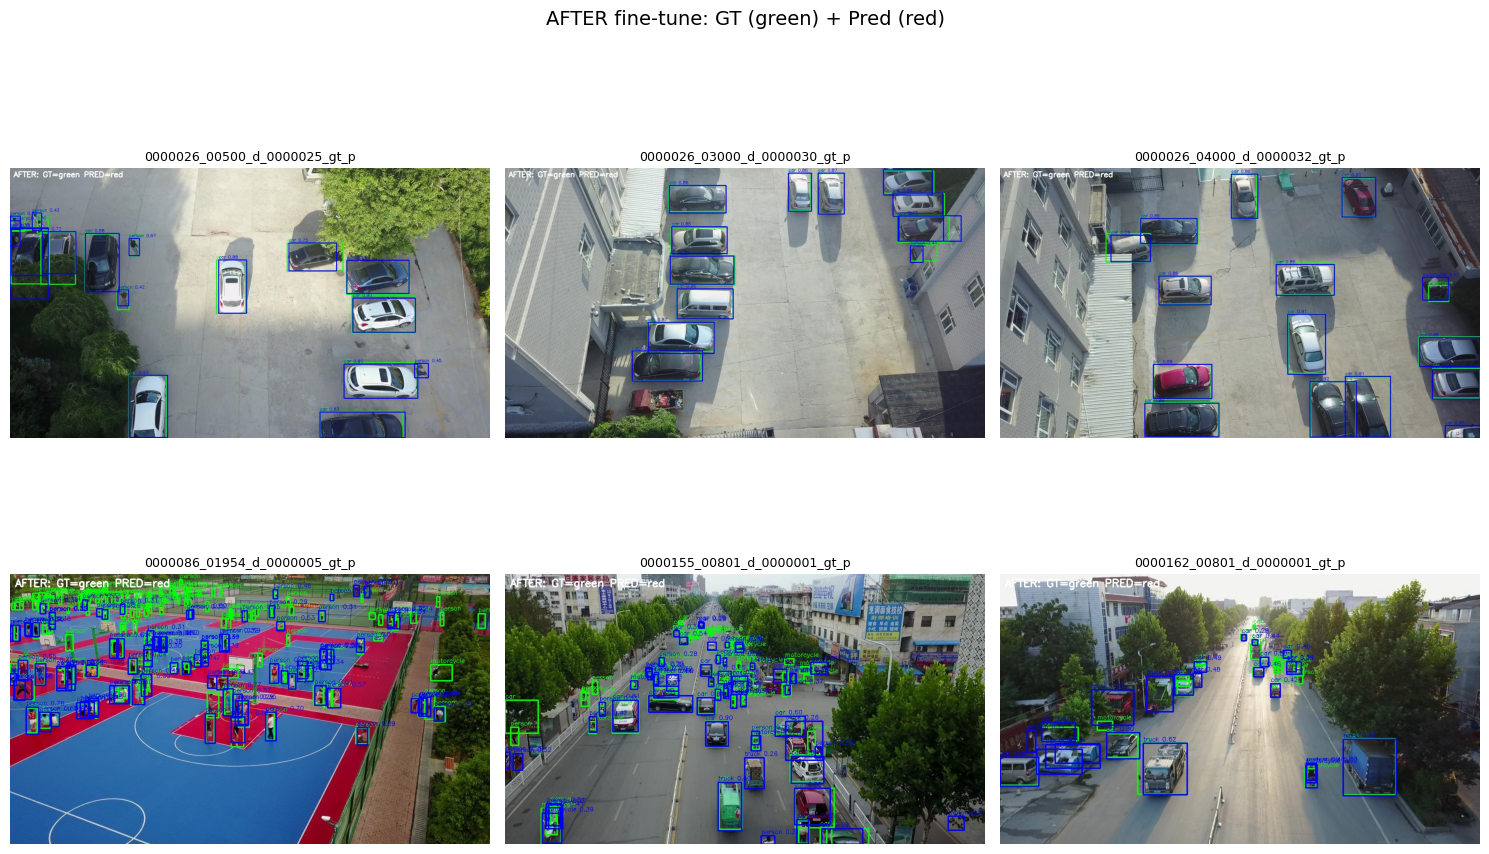

In [ ]:
viz_dir_after = OUT_DIR / "viz_after"
viz_dir_after.mkdir(exist_ok=True)

print(f"Running AFTER inference on {len(review_set)} review frames...")
for img_path in tqdm(review_set):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]
    gt_boxes, gt_labels = load_gt_boxes(VAL_LABELS / (img_path.stem + ".txt"), W, H)

    r = model_after.predict(str(img_path), imgsz=B0["imgsz"], conf=B0["conf"],
                            iou=B0["iou"], verbose=False)[0]
    pred_boxes, pred_labels = [], []
    if r.boxes is not None and len(r.boxes):
        for b in r.boxes:
            cls = int(b.cls.item())
            if cls not in COCO_NAMES:
                continue
            pred_boxes.append(b.xyxy[0].cpu().numpy().tolist())
            pred_labels.append(f"{COCO_NAMES[cls]} {float(b.conf.item()):.2f}")

    canvas = img.copy()
    canvas = draw_boxes(canvas, gt_boxes, gt_labels, COLORS_GT, 2)
    canvas = draw_boxes(canvas, pred_boxes, pred_labels, COLORS_PRED, 2)
    cv2.putText(canvas, "AFTER: GT=green PRED=red", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    cv2.imwrite(str(viz_dir_after / f"{img_path.stem}_gt_pred.jpg"), canvas)

print(f"Saved → {viz_dir_after}")

# Show 6 examples
viz_files = sorted(viz_dir_after.glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, vp in zip(axes.flat, viz_files):
    im = cv2.cvtColor(cv2.imread(str(vp)), cv2.COLOR_BGR2RGB)
    ax.imshow(im)
    ax.set_title(vp.stem[:28], fontsize=9)
    ax.axis("off")
plt.suptitle("AFTER fine-tune: GT (green) + Pred (red)", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Компроміс і рішення

Після отримання цифр заповни в звіті:
- чи підтвердилась H1
- час навчання, пам'ять інференсу
- **які ваги лишаємо** для наступного етапу: `yolov8n.pt` (B0) чи `best.pt` (fine-tuned) і чому

## 8. Артефакти

- Ноутбук з до/після
- `dz03_runs/finetune_b0/weights/best.pt` (+ хеш)
- `review_frames.txt`, viz_b0 / viz_after
- Part 2 звіту 04 + запис у журналі рішень

In [17]:
# Hash of best weights (for report / reproducibility outside Git)
import hashlib

def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

if best_pt.exists():
    sha = file_sha256(best_pt)
    print(f"best.pt: {best_pt}")
    print(f"SHA256:  {sha}")
    print(f"size:    {best_pt.stat().st_size / 1e6:.2f} MB")
else:
    print("best.pt not found — check training output path")

print("\n=== SUMMARY FOR REPORT ===")
print("B0 mAP50-95:", B0["mAP50-95"], " recall:", B0["recall"])
print("After mAP50-95:", AFTER.get("mAP50-95"), " recall:", AFTER.get("recall"))
print("Train epochs:", TRAIN_CFG["epochs"], " imgsz:", TRAIN_CFG["imgsz"])
print("Weights for next stage: decide B0 vs best.pt based on metrics above")

best.pt: /content/runs/detect/dz03_runs/finetune_b0/weights/best.pt
SHA256:  6d178921ef1eb7f905ec81fc692c216f49def442b261612640ca6e1a159e63ec
size:    6.52 MB

=== SUMMARY FOR REPORT ===
B0 mAP50-95: 0.0529  recall: 0.1063
After mAP50-95: 0.13295997307997068  recall: 0.2589585778432965
Train epochs: 15  imgsz: 640
Weights for next stage: decide B0 vs best.pt based on metrics above
